# 05 - Classificação com FCNN (Fully Convolutional Network)

Classificação dos espectrogramas (`mod_spectograms`) em 4 classes: `ictal`, `normal`, `pos_ictal` e `pre_ictal`. Treino e validação seguem o `splits.csv`.

Os três modelos têm o mesmo extrator (3 `Conv2D` 3x3 com 32, 64 e 128 filtros, cada uma com `MaxPooling2D`) e o mesmo treino (Adam, 30 épocas, mesma semente). Só muda o final:
- **CNN**: `Flatten` + `Dense(128)` + `Dropout(0.5)` + `Dense(4)`.
- **FCNN**: igual à CNN, com `Conv 1x1` no lugar das `Dense` e `GlobalAveragePooling2D` no lugar do `Flatten`. ← este notebook
- **Encoder-Decoder**: a FCNN com um decoder (3 `Conv2DTranspose`) antes da cabeça.

As métricas de teste estão no `06_metrics.ipynb`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dropout, Activation

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
tf.keras.utils.set_random_seed(0)
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Carregamento dos dados

In [2]:
splits = pd.read_csv(PROJECT_ROOT / 'data' / 'annotations' / 'splits.csv')
classes = sorted(splits['classe'].unique())
print(classes)

def carregar(conjunto):
    df = splits[splits['conjunto'] == conjunto]
    X, y = [], []
    for _, row in df.iterrows():
        caminho = PROJECT_ROOT / row['caminho'].replace('spectrograms', 'mod_spectograms')
        img = Image.open(caminho).convert('RGB').resize((224, 224))
        X.append(np.array(img) / 255.0)
        y.append(classes.index(row['classe']))
    return np.array(X, dtype='float32'), np.array(y)

X_train, y_train = carregar('treino')
X_val, y_val = carregar('validacao')
print(X_train.shape, X_val.shape)

def plotar_historico(history, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metrica, nome in zip(axes, ['loss', 'accuracy'], ['Perda', 'Acurácia']):
        ax.plot(history.history[metrica], label='Treinamento')
        ax.plot(history.history['val_' + metrica], label='Validação')
        ax.set_title(f'{titulo} — {nome}')
        ax.set_xlabel('Épocas')
        ax.set_ylabel(metrica)
        ax.legend()
    plt.tight_layout()
    plt.show()

['ICTAL', 'NORMAL', 'POS_ICTAL', 'PRE_ICTAL']


(100, 224, 224, 3) (20, 224, 224, 3)


## Arquitetura

In [3]:
fcnn = Sequential([
    Input(shape=(224, 224, 3)),
    # Extrator de features (igual nos três modelos)
    Conv2D(32, (3, 3), activation='relu', padding='same'),    # 224x224x32
    MaxPooling2D((2, 2)),                                     # 112x112x32
    Conv2D(64, (3, 3), activation='relu', padding='same'),    # 112x112x64
    MaxPooling2D((2, 2)),                                     # 56x56x64
    Conv2D(128, (3, 3), activation='relu', padding='same'),   # 56x56x128
    MaxPooling2D((2, 2)),                                     # 28x28x128
    # Classificador: a cabeça da CNN trocada por convoluções 1x1
    Conv2D(128, (1, 1), activation='relu'),                   # no lugar da Dense(128)
    Dropout(0.5),
    Conv2D(4, (1, 1)),                                        # no lugar da Dense(4): 1 mapa por classe
    GlobalAveragePooling2D(),                                 # 4 (no lugar do Flatten)
    Activation('softmax'),
])

fcnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 4)      │           516 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 4)              │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 4)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,276 (430.77 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

## Treinamento

In [4]:
fcnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_fcnn = fcnn.fit(X_train, y_train, epochs=30, validation_data=(X_val, y_val), verbose=2)

Epoch 1/30


4/4 - 12s - 3s/step - accuracy: 0.2300 - loss: 1.3875 - val_accuracy: 0.2500 - val_loss: 1.3712


Epoch 2/30


4/4 - 0s - 47ms/step - accuracy: 0.2500 - loss: 1.3818 - val_accuracy: 0.2500 - val_loss: 1.3559


Epoch 3/30


4/4 - 0s - 41ms/step - accuracy: 0.2500 - loss: 1.3783 - val_accuracy: 0.2500 - val_loss: 1.3342


... (50 outputs left out)

Epoch 29/30


4/4 - 0s - 38ms/step - accuracy: 0.3600 - loss: 1.2296 - val_accuracy: 0.3500 - val_loss: 1.3326


Epoch 30/30


4/4 - 0s - 39ms/step - accuracy: 0.4200 - loss: 1.2201 - val_accuracy: 0.3500 - val_loss: 1.3031


## Gráficos

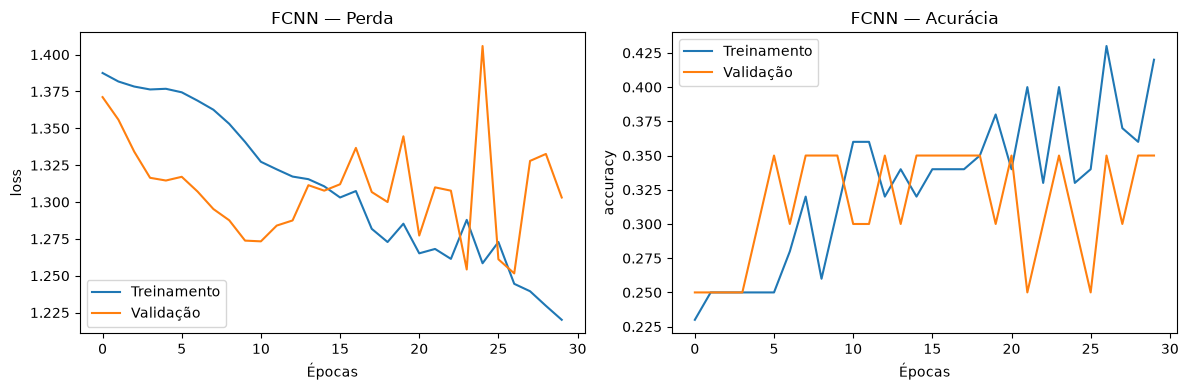

In [5]:
plotar_historico(history_fcnn, 'FCNN')

## Resultados (FCNN)

**Underfitting.** A loss de treino cai pouco (de 1,39 para 1,22), e a acurácia termina em 42% no treino e 35% na validação. Treino e validação andam juntos: a rede não decora, só aprende pouco em 30 épocas.

## Salvando o modelo

In [6]:
fcnn.save(PROJECT_ROOT / 'models' / 'modelo_fcnn.keras')

## Próximo passo

A avaliação no conjunto de teste está no notebook `06_metrics.ipynb`.